# Seminar 2 · Part C · Problem 1: setosa vs versicolor

We fit **logistic regression** with two features, the petal length $x_1$ and the petal width $x_2$, to tell **setosa** ($c = 0$) from **versicolor** ($c = 1$). This problem is **linearly separable**.

**Plan of this notebook**

1. Load the data
2. Look at the data (EDA)
3. Logistic regression from scratch
4. Fit it with gradient ascent
5. Decision boundaries: many lines work
6. Evaluate it

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris     # the Iris dataset comes with scikit-learn

SEED = 1                                   # fixed random seed: everyone gets the same split and the same numbers
SPECIES = ["setosa", "versicolor", "virginica"]
FEATURES = ["petal length", "petal width"] # x1 and x2, in cm
COLORS = {"setosa": "#2e9e6b", "versicolor": "#2a78d6", "virginica": "#8e4fc0"}   # the slide colours

## 1. Load the data

The Iris dataset, as in Seminar 1: 150 flowers, numbered **1 to 150**. We keep only **setosa** and **versicolor** (flowers 1 to 100) and only the two petal measurements.

The label: $c^{(i)} = 0$ for setosa, $c^{(i)} = 1$ for versicolor.

In [2]:
iris = load_iris()
data = pd.DataFrame(iris.data[:, 2:4], columns=FEATURES)   # columns 2 and 3: petal length, petal width
data["species"] = [SPECIES[k] for k in iris.target]
data.index = range(1, len(data) + 1)                       # flower numbers 1, 2, ..., 150

data = data[data["species"].isin(["setosa", "versicolor"])].copy()
data["c"] = (data["species"] == "versicolor").astype(int)  # the label: 1 for versicolor, 0 for setosa

X = data[FEATURES].to_numpy()      # one row per flower: (x1, x2)
c = data["c"].to_numpy()           # one label per flower
m = len(c)
print("m =", m, "flowers")
data.loc[[1, 51]]                  # one flower of each species

m = 100 flowers


,petal length,petal width,species,c
1,1.4,0.2,setosa,0
51,4.7,1.4,versicolor,1


## 2. Look at the data (EDA)

In [3]:
print(data["species"].value_counts())
data.groupby("species")[FEATURES].agg(["min", "max"])

species
setosa        50
versicolor    50
Name: count, dtype: int64


petal length      petal width     
                    min  max         min  max
species                                      
setosa              1.0  1.9         0.1  0.6
versicolor          3.0  5.1         1.0  1.8

The largest setosa petal length (1.9 cm) is smaller than the smallest versicolor petal length (3.0 cm). The same holds for the width (0.6 cm and 1.0 cm). So a line can separate the two species: the data are **linearly separable**.

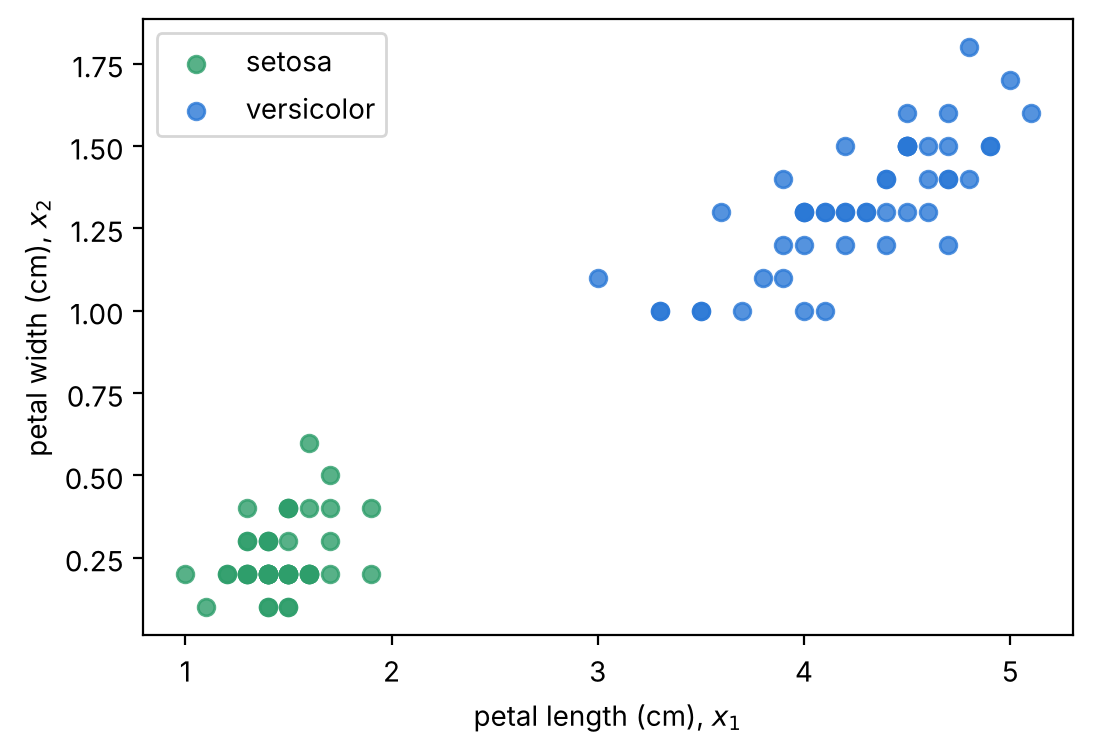

In [4]:
plt.figure(figsize=(6, 4))
for name in ["setosa", "versicolor"]:
    part = data[data["species"] == name]
    plt.scatter(part["petal length"], part["petal width"], color=COLORS[name], label=name, alpha=0.8)
plt.xlabel("petal length (cm), $x_1$")
plt.ylabel("petal width (cm), $x_2$")
plt.legend()
plt.show()

## 3. Logistic regression from scratch

### The model and the log-likelihood (Parts A and B)

$$p_{\alpha,\beta}(x) = \operatorname{lgf}(\beta^T x + \alpha), \qquad \operatorname{lgf}(\ell) = \frac{1}{1 + e^{-\ell}},$$

$$\log \mathcal{L}(\alpha, \beta) = \sum_{i=1}^{m} \Big[c^{(i)} \log p_{\alpha,\beta}\big(x^{(i)}\big) + \big(1 - c^{(i)}\big) \log\Big(1 - p_{\alpha,\beta}\big(x^{(i)}\big)\Big)\Big].$$

### Gradient ascent (Part B)

Start at $\alpha^{(0)} = 0$, $\beta^{(0)} = 0$. In each step, add $\gamma$ times the gradient:

$$\frac{\partial \log \mathcal{L}}{\partial \alpha} = \sum_{i=1}^{m} \Big(c^{(i)} - p_{\alpha,\beta}\big(x^{(i)}\big)\Big), \qquad \frac{\partial \log \mathcal{L}}{\partial \beta_j} = \sum_{i=1}^{m} \Big(c^{(i)} - p_{\alpha,\beta}\big(x^{(i)}\big)\Big)\, x^{(i)}_j.$$

### The decision rule (Part A)

Predict $\hat{c} = 1$ when $\beta^T x + \alpha > 0$, and $\hat{c} = 0$ otherwise.

In [5]:
def lgf(l):
    """The logistic function: lgf(l) = 1 / (1 + e^(-l))."""
    return 1 / (1 + np.exp(-l))


def log_likelihood(alpha, beta, X, c):
    """log L(alpha, beta) for the items in the rows of X, with the labels c.
    We write  c log p + (1 - c) log(1 - p)  as  c * l - log(1 + e^l),  with l = beta^T x + alpha:
    the same number, but it never takes the log of 0."""
    l = X @ beta + alpha                            # the logit of every item
    return np.sum(c * l - np.logaddexp(0, l))       # np.logaddexp(0, l) = log(1 + e^l)


def gradient_ascent(X, c, gamma, steps, keep=()):
    """Gradient ascent on log L: start at 0, then `steps` steps of size gamma.
    Returns the last (alpha, beta), and a dictionary {t: (alpha_t, beta_t)} for the steps t in `keep`."""
    alpha, beta = 0.0, np.zeros(X.shape[1])         # alpha^(0) = 0, beta^(0) = (0, ..., 0)
    kept = {}
    for t in range(1, steps + 1):
        error = c - lgf(X @ beta + alpha)           # the error of each item: c^(i) - p(x^(i))
        alpha = alpha + gamma * np.sum(error)       # step for alpha: gamma * (sum of the errors)
        beta = beta + gamma * (error @ X)           # step for beta_j: gamma * (sum of error * x_j), for every j
        if t in keep:
            kept[t] = (alpha, beta.copy())
    return (alpha, beta), kept


def predict(alpha, beta, X):
    """The decision rule: 1 when beta^T x + alpha > 0, else 0. One prediction per row of X."""
    return (X @ beta + alpha > 0).astype(int)

## 4. Fit it with gradient ascent

Learning rate $\gamma = 0.002$. (With a larger one, $\gamma = 0.01$, the first step already goes downhill: try it.)

We run **100,000 steps**, and keep $\alpha^{(t)}$, $\beta^{(t)}$ at some steps $t$ to look at later. This takes a few seconds.

In [6]:
GAMMA, STEPS = 0.002, 100_000
show = [100, 1_000, 10_000, 100_000]
keep = set(show)                           # the steps t where we keep alpha^(t), beta^(t)

(alpha_last, beta_last), path = gradient_ascent(X, c, GAMMA, STEPS, keep)

table = pd.DataFrame(
    [(t, path[t][0], path[t][1][0], path[t][1][1], np.sum(predict(*path[t], X) != c)) for t in show[:3]],
    columns=["step t", "alpha", "beta_1", "beta_2", "flowers on the wrong side"]).set_index("step t")
table.round(2)

,alpha,beta_1,beta_2,flowers on the wrong side
step t,,,,
100,-2.40,0.76,1.06,0
1000,-6.78,1.87,2.82,0
10000,-11.74,3.25,4.85,0


**No mistakes** already after 100 steps.

## 5. Decision boundaries: many lines work

The **decision boundary** is the set of points $x$ where $\beta^T x + \alpha = 0$. With two features it is a line, and we draw it by solving for the petal width:

$$x_2 = -\frac{\beta_1 x_1 + \alpha}{\beta_2} \qquad (\beta_2 \neq 0).$$

Below: the line of gradient ascent at step 100,000, and two lines we picked by hand, petal length $= 2.5$ and petal width $= 0.8$. A vertical line $x_1 = 2.5$ is $\beta = (1, 0)$, $\alpha = -2.5$; a horizontal line $x_2 = 0.8$ is $\beta = (0, 1)$, $\alpha = -0.8$.

gradient ascent, t = 100,000    flowers on the wrong side: 0
x1 = 2.5                        flowers on the wrong side: 0
x2 = 0.8                        flowers on the wrong side: 0


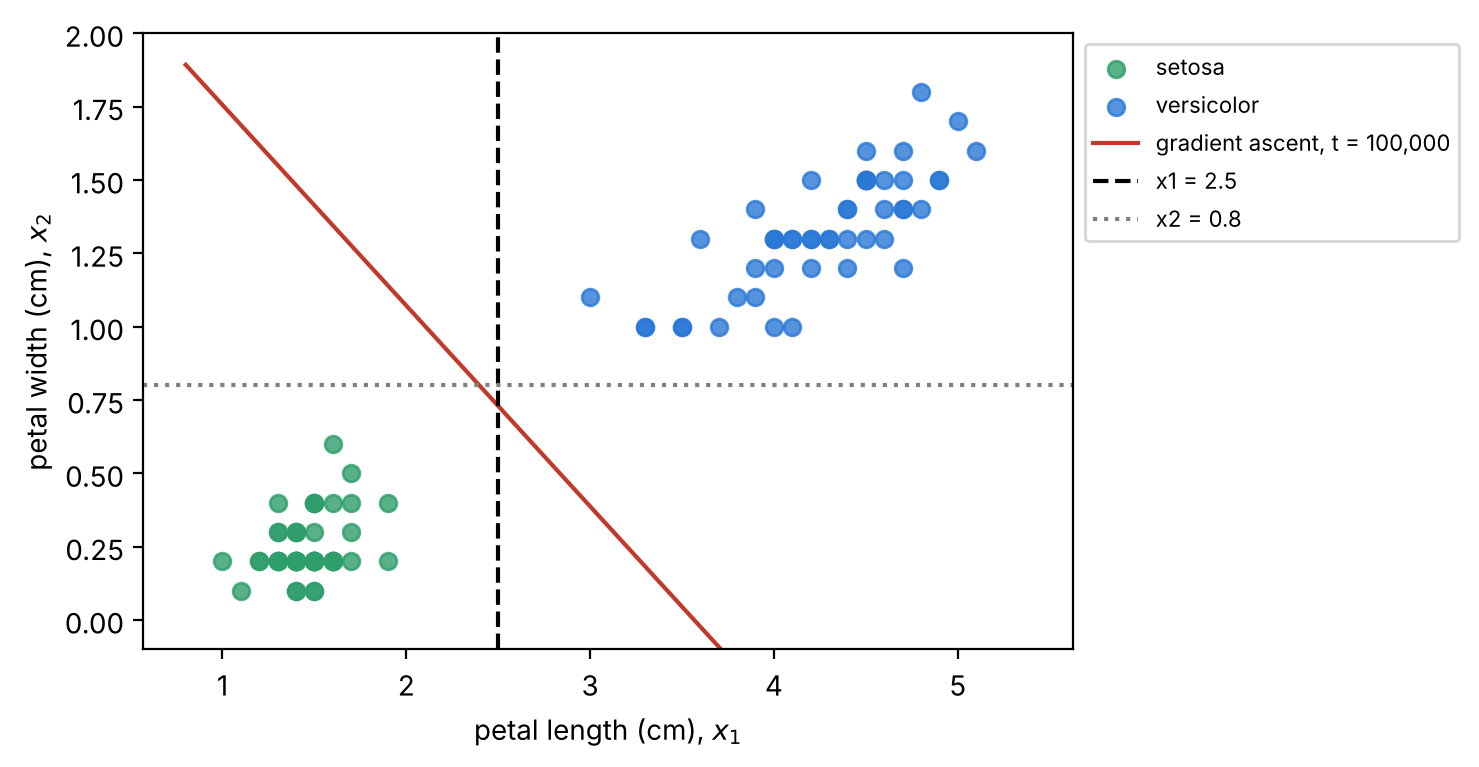

In [7]:
lines = {
    "gradient ascent, t = 100,000": path[100_000],
    "x1 = 2.5": (-2.5, np.array([1.0, 0.0])),
    "x2 = 0.8": (-0.8, np.array([0.0, 1.0])),
}
for name, (a, b) in lines.items():
    print(f"{name:30}  flowers on the wrong side: {np.sum(predict(a, b, X) != c)}")

alpha_t, beta_t = lines["gradient ascent, t = 100,000"]
x1 = np.linspace(0.8, 5.4, 2)
plt.figure(figsize=(6, 4))
for name in ["setosa", "versicolor"]:
    part = data[data["species"] == name]
    plt.scatter(part["petal length"], part["petal width"], color=COLORS[name], label=name, alpha=0.8)
plt.plot(x1, -(beta_t[0] * x1 + alpha_t) / beta_t[1], color="#c0392b", label="gradient ascent, t = 100,000")
plt.axvline(2.5, color="black", linestyle="--", label="x1 = 2.5")
plt.axhline(0.8, color="gray", linestyle=":", label="x2 = 0.8")
plt.ylim(-0.1, 2.0)
plt.xlabel("petal length (cm), $x_1$")
plt.ylabel("petal width (cm), $x_2$")
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))   # the legend outside, on the right
plt.show()

Three different lines, each with **0 mistakes**: for separable data the separating line is **not unique**.

## 6. Evaluate it

As in Seminar 1: a random **training set** (80% of the flowers) and a **test set** (the other 20%). We fit on the training set only, with a fixed number of steps, 10,000.

Training set: 80 flowers;  Test set: 20 flowers
training error: 0.0
test error:     0.0


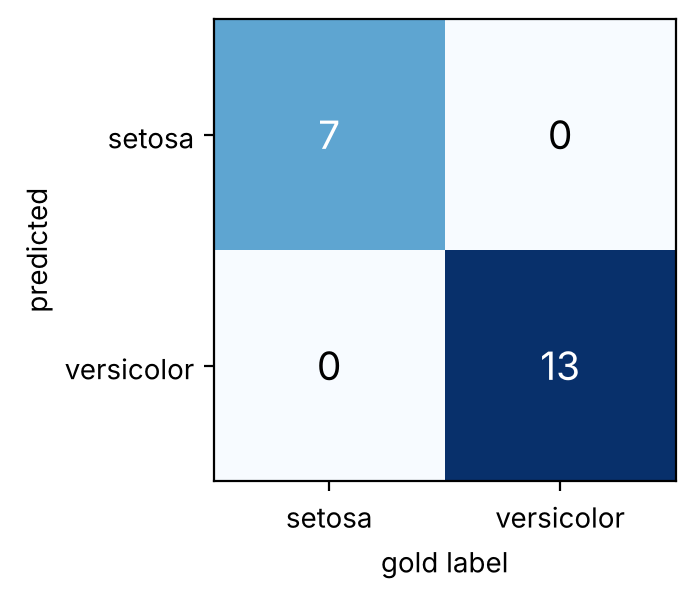

In [8]:
rng = np.random.default_rng(SEED)
order = rng.permutation(m)                 # the flowers in a random order
n_train = int(0.8 * m)
train, test = order[:n_train], order[n_train:]
print("Training set:", len(train), "flowers;  Test set:", len(test), "flowers")

(alpha_hat, beta_hat), _ = gradient_ascent(X[train], c[train], GAMMA, 10_000)
predicted = predict(alpha_hat, beta_hat, X[test])

confusion = pd.crosstab(pd.Series(predicted, name="predicted"), pd.Series(c[test], name="gold label"))
print("training error:", np.mean(predict(alpha_hat, beta_hat, X[train]) != c[train]))
print("test error:    ", np.mean(predicted != c[test]))

# The confusion matrix as a picture: rows = predicted class, columns = gold label (as in Seminar 1)
confusion = confusion.reindex(index=[0, 1], columns=[0, 1], fill_value=0)   # keep both rows and columns, even if a count is 0
fig, ax = plt.subplots(figsize=(3.5, 3))
ax.imshow(confusion, cmap="Blues")                 # darker blue = more flowers
for row in range(2):
    for col in range(2):
        count = confusion.iloc[row, col]
        color = "white" if count > confusion.to_numpy().max() / 2 else "black"   # white text on dark squares
        ax.text(col, row, count, ha="center", va="center", fontsize=14, color=color)
names = ["setosa", "versicolor"]   # label 0, label 1
ax.set_xticks([0, 1], names)
ax.set_yticks([0, 1], names)
ax.set_xlabel("gold label")
ax.set_ylabel("predicted")
plt.show()

All test flowers are right: Problem 1 is easy for a line.

## Summary

- Problem 1 is **linearly separable**: a line puts every flower on the right side.
- Gradient ascent finds such a line quickly: no mistakes after 100 steps.
- The **decision boundary** $\beta^T x + \alpha = 0$ is a line; for separable data it is **not unique**.